# DS605 Lab Assignment 7: Image Representation, PCA, Eigenfaces and Face Recognition

**Dataset:** AT&T Database of Faces (ORL)

This notebook follows Parts A–D of the assignment. PCA is implemented with **NumPy linear algebra** (eigendecomposition and SVD); Scikit-learn is used only for the final classifier comparison.

## Before running
1. Download the AT&T/ORL face database and extract it.
2. Put the subject folders (`s1`, `s2`, ..., `s40`) inside a folder named `data/orl_faces/` beside this notebook. Each subject folder should contain images such as `1.pgm`, `2.pgm`, etc.
3. Run the notebook from top to bottom.

The notebook creates figures in `outputs/` and prints the recognition results. If your dataset is stored somewhere else, change `DATA_DIR` in the next cell.

## 1. Import libraries and set paths

In [2]:
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("data/orl_faces")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

np.random.seed(42)

## Part A — Image representation

Read images as grayscale matrices, inspect their size and intensity range, flatten each image into one feature vector, and keep its subject label. The split is made separately for each subject so every subject appears in both training and test sets.

In [3]:
# Find subject folders such as s1, s2, ..., s40
subject_dirs = sorted(
    [p for p in DATA_DIR.iterdir() if p.is_dir() and p.name.lower().startswith("s")],
    key=lambda p: int(p.name[1:]) if p.name[1:].isdigit() else p.name
)

if not subject_dirs:
    raise FileNotFoundError(
        f"No subject folders found in {DATA_DIR.resolve()}. "
        "Place folders s1, s2, ... inside data/orl_faces/."
    )

images = []
labels = []
image_paths = []

for subject_dir in subject_dirs:
    files = sorted(
        [p for p in subject_dir.iterdir() if p.suffix.lower() in [".pgm", ".png", ".jpg", ".jpeg", ".bmp"]]
    )
    for path in files:
        image = Image.open(path).convert("L")
        images.append(np.asarray(image, dtype=np.float32))
        labels.append(subject_dir.name)
        image_paths.append(path)

images = np.array(images)
labels = np.array(labels)

print("Number of images:", len(images))
print("Number of subjects:", len(np.unique(labels)))
print("Image matrix dimensions:", images.shape)
print("One image dimensions:", images[0].shape)
print("Pixel intensity range:", images.min(), "to", images.max())

Number of images: 400
Number of subjects: 40
Image matrix dimensions: (400, 112, 92)
One image dimensions: (112, 92)
Pixel intensity range: 0.0 to 251.0


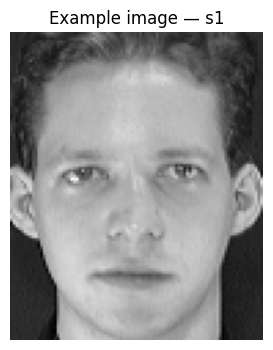

Flattened image matrix shape: (400, 10304)
Each row is one image; each column is one pixel feature.


In [4]:
# Show a sample grayscale image
plt.figure(figsize=(4, 4))
plt.imshow(images[0], cmap="gray")
plt.title(f"Example image — {labels[0]}")
plt.axis("off")
plt.show()

# Flatten every image into one row
X = images.reshape(len(images), -1)
y = labels.copy()

print("Flattened image matrix shape:", X.shape)
print("Each row is one image; each column is one pixel feature.")

In [5]:
# Reproducible train-test split with at least one test image per subject.
# Use 2 test images per subject when that subject has at least 3 images.
train_indices = []
test_indices = []
rng = np.random.default_rng(42)

for subject in np.unique(y):
    subject_indices = np.where(y == subject)[0]
    rng.shuffle(subject_indices)
    n_test = max(1, int(round(0.2 * len(subject_indices))))
    n_test = min(n_test, len(subject_indices) - 1)
    test_indices.extend(subject_indices[:n_test])
    train_indices.extend(subject_indices[n_test:])

train_indices = np.array(sorted(train_indices))
test_indices = np.array(sorted(test_indices))

X_train, X_test = X[train_indices], X[test_indices]
y_train, y_test = y[train_indices], y[test_indices]

print("Training images:", len(X_train))
print("Test images:", len(X_test))
print("Subjects in training:", len(np.unique(y_train)))
print("Subjects in test:", len(np.unique(y_test)))

Training images: 320
Test images: 80
Subjects in training: 40
Subjects in test: 40


## Part B — PCA, eigenfaces and compression

First calculate the mean face and center the training images. The pixel covariance matrix would be very large, so eigendecomposition is performed on the smaller **sample-space Gram matrix** \(X_c X_c^T\). Its eigenvectors are mapped back to pixel space to obtain eigenfaces. We also calculate principal directions directly with NumPy SVD and compare the two approaches.

The signs of eigenvectors can differ without changing the PCA result, so the comparison uses the absolute cosine similarity between corresponding directions.

In [6]:
# Mean face and mean-centering
mean_face = X_train.mean(axis=0)
X_train_centered = X_train - mean_face

# Covariance/eigendecomposition in sample space
start = time.time()
gram_matrix = X_train_centered @ X_train_centered.T
eigenvalues, sample_eigenvectors = np.linalg.eigh(gram_matrix)
eig_time = time.time() - start

# Sort eigenvalues from largest to smallest
order = np.argsort(eigenvalues)[::-1]
eigenvalues = np.maximum(eigenvalues[order], 0)
sample_eigenvectors = sample_eigenvectors[:, order]

# Map sample-space eigenvectors into pixel-space principal directions
eps = 1e-10
valid = eigenvalues > eps
eigenvalues = eigenvalues[valid]
sample_eigenvectors = sample_eigenvectors[:, valid]
components_eig = X_train_centered.T @ sample_eigenvectors
components_eig = components_eig / np.linalg.norm(components_eig, axis=0, keepdims=True)

print("Eigendecomposition time (seconds):", round(eig_time, 3))
print("Number of non-zero principal directions:", components_eig.shape[1])

Eigendecomposition time (seconds): 0.045
Number of non-zero principal directions: 320


In [7]:
# SVD directly on the centered training matrix
start = time.time()
U, singular_values, Vt = np.linalg.svd(X_train_centered, full_matrices=False)
svd_time = time.time() - start
components_svd = Vt.T

# Compare the first few directions; signs may differ
n_compare = min(10, components_eig.shape[1], components_svd.shape[1])
similarities = [
    abs(np.dot(components_eig[:, i], components_svd[:, i]))
    for i in range(n_compare)
]

print("SVD time (seconds):", round(svd_time, 3))
print("Absolute cosine similarities for first components:")
print(np.round(similarities, 4))

SVD time (seconds): 2.778
Absolute cosine similarities for first components:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### Explained variance

For each principal direction, the explained variance is its eigenvalue divided by the sum of all eigenvalues. We keep the **minimum number of components that reaches at least 90% cumulative explained variance**.

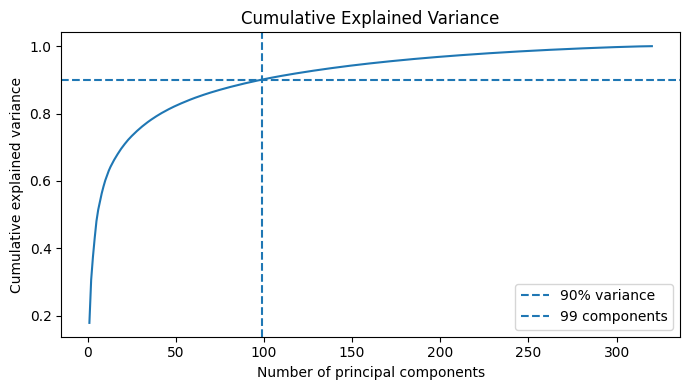

Minimum components for at least 90% variance: 99
Cumulative variance retained: 0.9009


In [8]:
explained_variance_ratio = eigenvalues / np.sum(eigenvalues)
cumulative_variance = np.cumsum(explained_variance_ratio)
n_components_90 = int(np.searchsorted(cumulative_variance, 0.90) + 1)

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance)
plt.axhline(0.90, linestyle="--", label="90% variance")
plt.axvline(n_components_90, linestyle="--", label=f"{n_components_90} components")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "explained_variance.png", dpi=150)
plt.show()

print("Minimum components for at least 90% variance:", n_components_90)
print("Cumulative variance retained:", round(cumulative_variance[n_components_90 - 1], 4))

### Visualize eigenfaces

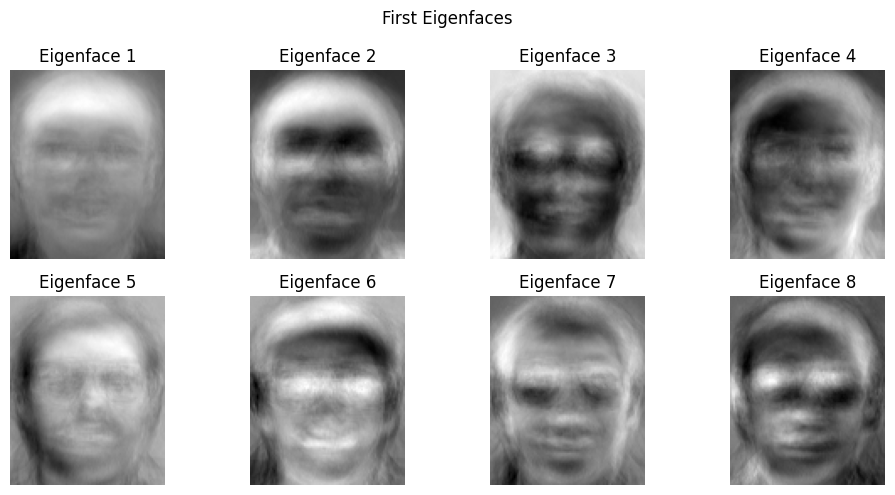

In [9]:
n_show = min(8, n_components_90)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    if i < n_show:
        ax.imshow(components_eig[:, i].reshape(images.shape[1:]), cmap="gray")
        ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")
plt.suptitle("First Eigenfaces")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eigenfaces.png", dpi=150)
plt.show()

### Project, reconstruct and compare storage

Project the centered images into the selected PCA space. Reconstruction is performed by projecting back from PCA space and adding the mean face. Storage is compared by counting numeric values: original pixels versus the mean face plus the retained component directions and each image's PCA coefficients. This is a simple estimate and does not include file-format overhead.

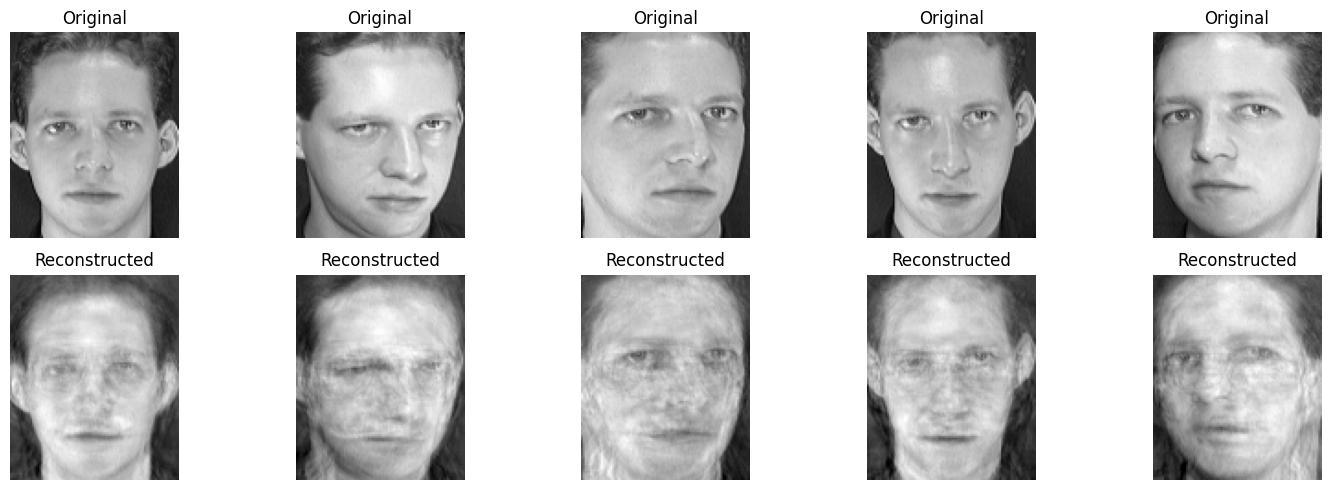

Mean squared reconstruction error for displayed examples: 153.43
Original training pixel values: 3297280
Approximate PCA storage values (mean + components + coefficients): 1062080
Approximate storage ratio (PCA/original): 0.322


In [10]:
components = components_eig[:, :n_components_90]

X_train_pca = (X_train - mean_face) @ components
X_test_pca = (X_test - mean_face) @ components

# Reconstruct a few training faces
n_reconstruct = min(5, len(X_train))
reconstructed = X_train_pca[:n_reconstruct] @ components.T + mean_face

fig, axes = plt.subplots(2, n_reconstruct, figsize=(3 * n_reconstruct, 5))
for i in range(n_reconstruct):
    axes[0, i].imshow(X_train[i].reshape(images.shape[1:]), cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")
    axes[1, i].imshow(
        np.clip(reconstructed[i].reshape(images.shape[1:]), 0, 255),
        cmap="gray"
    )
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "reconstruction_examples.png", dpi=150)
plt.show()

mse = np.mean((X_train[:n_reconstruct] - reconstructed) ** 2)
print("Mean squared reconstruction error for displayed examples:", round(float(mse), 2))

n_images, n_pixels = X_train.shape
original_values = n_images * n_pixels
pca_values = n_pixels + n_pixels * n_components_90 + n_images * n_components_90
print("Original training pixel values:", original_values)
print("Approximate PCA storage values (mean + components + coefficients):", pca_values)
print("Approximate storage ratio (PCA/original):", round(pca_values / original_values, 3))

## Part C — Recognition in PCA space

For each test image, find the training image with the smallest Euclidean distance. We calculate this once with raw pixel vectors and once with PCA features. The prediction is the subject label of the closest training image.

In [11]:
def nearest_neighbor_predict(train_features, train_labels, test_features):
    predictions = []
    for test_row in test_features:
        distances = np.sqrt(np.sum((train_features - test_row) ** 2, axis=1))
        closest_index = np.argmin(distances)
        predictions.append(train_labels[closest_index])
    return np.array(predictions)

# Raw-pixel baseline
raw_predictions = nearest_neighbor_predict(X_train, y_train, X_test)

# PCA-space matching
pca_predictions = nearest_neighbor_predict(X_train_pca, y_train, X_test_pca)

raw_accuracy = np.mean(raw_predictions == y_test)
pca_accuracy = np.mean(pca_predictions == y_test)

print(f"Nearest-neighbor accuracy using raw pixels: {raw_accuracy:.3f}")
print(f"Nearest-neighbor accuracy using PCA features: {pca_accuracy:.3f}")

Nearest-neighbor accuracy using raw pixels: 0.988
Nearest-neighbor accuracy using PCA features: 0.988


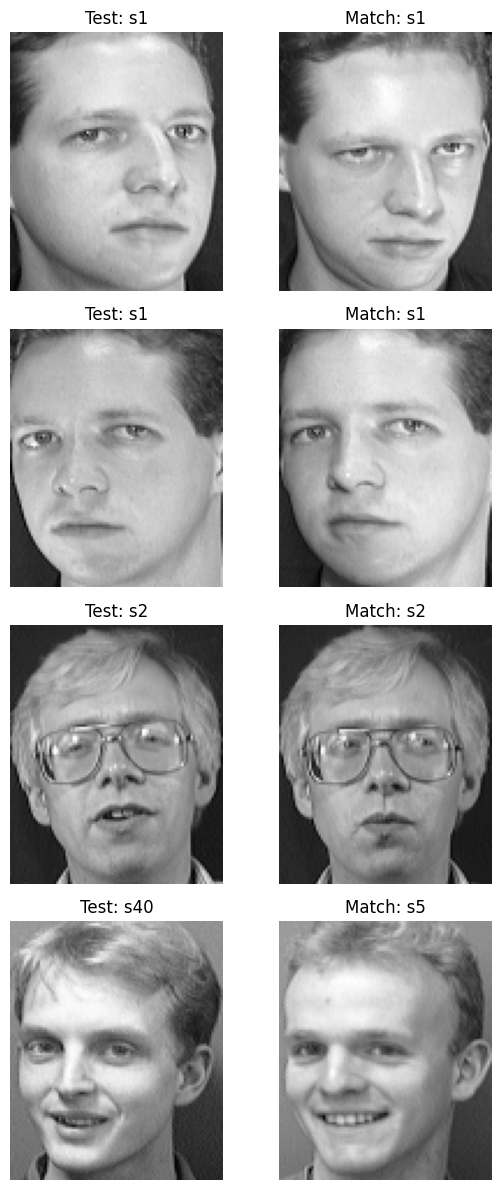

In [12]:
# Inspect a few correct and incorrect PCA matches
correct_indices = np.where(pca_predictions == y_test)[0]
incorrect_indices = np.where(pca_predictions != y_test)[0]
selected = list(correct_indices[:3]) + list(incorrect_indices[:3])
selected = selected[:6]

if selected:
    fig, axes = plt.subplots(len(selected), 2, figsize=(6, 3 * len(selected)))
    if len(selected) == 1:
        axes = np.array([axes])
    for row, test_i in enumerate(selected):
        image_i = test_indices[test_i]
        axes[row, 0].imshow(X[image_i].reshape(images.shape[1:]), cmap="gray")
        axes[row, 0].set_title(f"Test: {y_test[test_i]}")
        axes[row, 0].axis("off")

        # Show the closest training face in PCA space
        distances = np.sqrt(np.sum((X_train_pca - X_test_pca[test_i]) ** 2, axis=1))
        nearest_i = np.argmin(distances)
        axes[row, 1].imshow(X[train_indices[nearest_i]].reshape(images.shape[1:]), cmap="gray")
        axes[row, 1].set_title(f"Match: {pca_predictions[test_i]}")
        axes[row, 1].axis("off")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "recognition_matches.png", dpi=150)
    plt.show()
else:
    print("No matches to display.")

## Part D — Traditional machine-learning classifiers

Use the PCA features to train two traditional classifiers: **K-Nearest Neighbors (KNN)** and **Support Vector Machine (SVM)**. Scikit-learn is used only here, as permitted by the assignment. We also try a few component counts to see how compact representations affect recognition.

In [13]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Train two classifiers using the 90%-variance PCA representation
knn = KNeighborsClassifier(n_neighbors=1)
svm = SVC(kernel="linear", C=1.0)

knn.fit(X_train_pca, y_train)
svm.fit(X_train_pca, y_train)

knn_predictions = knn.predict(X_test_pca)
svm_predictions = svm.predict(X_test_pca)

results = [
    ("Raw pixels — nearest neighbor", accuracy_score(y_test, raw_predictions)),
    ("PCA — nearest neighbor", accuracy_score(y_test, pca_predictions)),
    ("PCA — KNN (k=1)", accuracy_score(y_test, knn_predictions)),
    ("PCA — linear SVM", accuracy_score(y_test, svm_predictions)),
]

for name, accuracy in results:
    print(f"{name:32s} accuracy = {accuracy:.3f}")

Raw pixels — nearest neighbor    accuracy = 0.988
PCA — nearest neighbor           accuracy = 0.988
PCA — KNN (k=1)                  accuracy = 0.988
PCA — linear SVM                 accuracy = 0.988


In [14]:
# Experiment with compact component counts.
# Counts larger than the available PCA directions are skipped.
component_options = [10, 20, 40, 60, n_components_90]
component_options = sorted(set(c for c in component_options if c <= components_eig.shape[1]))

experiment_rows = []
for n_comp in component_options:
    comp = components_eig[:, :n_comp]
    train_features = (X_train - mean_face) @ comp
    test_features = (X_test - mean_face) @ comp

    knn_model = KNeighborsClassifier(n_neighbors=1)
    svm_model = SVC(kernel="linear", C=1.0)
    knn_model.fit(train_features, y_train)
    svm_model.fit(train_features, y_train)

    experiment_rows.append({
        "Components": n_comp,
        "Variance retained": float(cumulative_variance[n_comp - 1]),
        "1-NN accuracy": accuracy_score(y_test, knn_model.predict(test_features)),
        "Linear SVM accuracy": accuracy_score(y_test, svm_model.predict(test_features)),
    })

print(f"{'Components':>10} {'Variance':>12} {'1-NN accuracy':>16} {'SVM accuracy':>14}")
for row in experiment_rows:
    print(
        f"{row['Components']:>10} "
        f"{row['Variance retained']:>11.3f} "
        f"{row['1-NN accuracy']:>16.3f} "
        f"{row['Linear SVM accuracy']:>14.3f}"
    )

Components     Variance    1-NN accuracy   SVM accuracy
        10       0.602            0.938          0.963
        20       0.703            0.988          0.988
        40       0.795            1.000          0.988
        60       0.845            1.000          0.988
        99       0.901            0.988          0.988


## Observations and conclusion

After running the notebook, use the printed results to write a few observations:

- How many components were needed to retain at least 90% of the variance?
- How similar were the first PCA directions from eigendecomposition and SVD?
- How does reconstruction quality change when more components are retained?
- Did PCA nearest-neighbor recognition perform better or worse than raw-pixel matching?
- Which of KNN and SVM performed best on this train-test split?
- How much storage was needed for the PCA representation compared with the original pixel values?

Results depend on the dataset files and the fixed random seed. Do not claim that one method is best unless your printed results support that conclusion.